# 02 · Delivery Risk Analysis

**Business problem:** more than half of all orders arrive late. Operations wants to know **why, where to act first, and what fixing it is worth.**

| # | Business question |
|---|---|
| 1 | How big is the late-delivery problem? |
| 2 | Which shipping modes cause it: promised vs actual days? |
| 3 | Is it a regional, product or customer problem? |
| 4 | Where should the team act first (risk ranking)? |
| 5 | Does late delivery cost profit, and where is profit actually lost? |
| 6 | Where is fraud risk concentrated? |
| 7 | What if delivery promises matched reality? |

Delivery metrics exclude cancelled shipments (`is_cancelled`), which never shipped.

In [1]:
import duckdb
import pandas as pd
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = (ROOT / "data" / "raw" / "DataCoSupplyChainDataset.csv").as_posix()
PROCESSED = ROOT / "data" / "processed"
IMAGES = ROOT / "images"
PROCESSED.mkdir(parents=True, exist_ok=True)
IMAGES.mkdir(parents=True, exist_ok=True)

con = duckdb.connect()
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
pd.set_option("display.max_columns", 30)

con.sql(f"CREATE OR REPLACE TABLE orders AS SELECT * FROM read_parquet('{(PROCESSED / 'supply_chain_clean.parquet').as_posix()}')")
con.sql("CREATE OR REPLACE VIEW shipped AS SELECT * FROM orders WHERE NOT is_cancelled")
q = lambda sql: con.sql(sql).df()

In [2]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

BLUE, ORANGE, GREY, INK, LIGHT = "#2a78d6", "#eb6834", "#52514e", "#0b0b0b", "#b7d3f6"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": GREY,
    "xtick.color": GREY, "ytick.color": GREY,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlelocation": "left",
    "font.size": 10,
})
pct = mtick.PercentFormatter(xmax=1, decimals=0)

def save(fig, name):
    fig.tight_layout()
    fig.savefig(IMAGES / name, dpi=150, bbox_inches="tight")
    plt.show()

## Q1 · How big is the problem?

In [3]:
q("""
    SELECT COUNT(*)                          AS shipped_lines,
           SUM(is_late)                      AS late_lines,
           ROUND(100 * AVG(is_late), 1)      AS late_rate_pct,
           ROUND(AVG(delay_days) FILTER (WHERE is_late = 1), 2) AS avg_days_late_when_late
    FROM shipped
""")

,shipped_lines,late_lines,late_rate_pct,avg_days_late_when_late
0,172765,"98,977.00",57.30,1.62


**57% of shipped order lines arrive after the promised date**, about 99,000 lines. That is a customer-experience problem large enough to be systemic, not a few bad shipments.

## Q2 · Which shipping modes cause it?

In [4]:
modes = q("""
    SELECT shipping_mode,
           COUNT(*)                          AS lines,
           ROUND(AVG(days_promised), 2)      AS avg_days_promised,
           ROUND(AVG(days_actual), 2)        AS avg_days_actual,
           ROUND(AVG(is_late), 3)            AS late_rate
    FROM shipped
    GROUP BY shipping_mode
    ORDER BY avg_days_promised
""")
modes

,shipping_mode,lines,avg_days_promised,avg_days_actual,late_rate
0,Same Day,9293,0.00,0.48,0.48
1,First Class,26513,1.00,2.00,1.00
2,Second Class,33806,2.00,3.99,0.80
3,Standard Class,103153,4.00,3.99,0.40


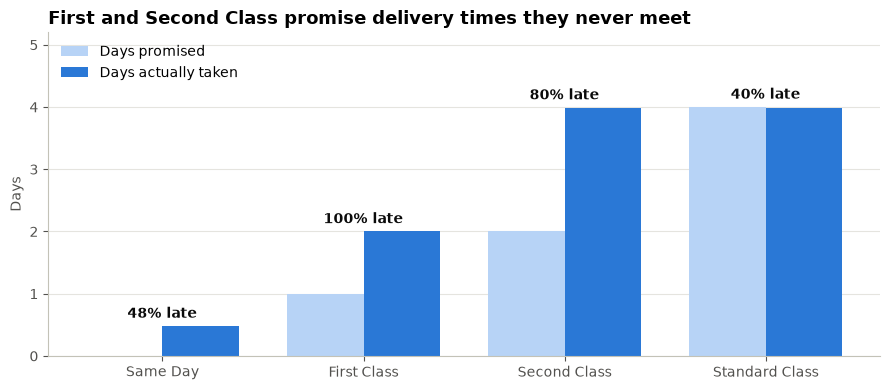

In [5]:
import numpy as np
x = np.arange(len(modes)); w = 0.38
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - w/2, modes["avg_days_promised"], w, color=LIGHT, label="Days promised")
ax.bar(x + w/2, modes["avg_days_actual"],   w, color=BLUE,  label="Days actually taken")
for i, r in modes.iterrows():
    ax.annotate(f"{r.late_rate:.0%} late", (i, max(r.avg_days_promised, r.avg_days_actual)),
                xytext=(0, 6), textcoords="offset points", ha="center", color=INK, fontsize=10, fontweight="bold")
ax.set_xticks(x, modes["shipping_mode"])
ax.set_ylim(0, 5.2); ax.set_ylabel("Days")
ax.legend(frameon=False, loc="upper left")
ax.set_title("First and Second Class promise delivery times they never meet")
ax.grid(axis="y", color="#e5e4df"); ax.set_axisbelow(True)
save(fig, "01_promised_vs_actual.png")

**This is the root cause.**
- **First Class** promises 1 day and *always* takes 2, so it is **100% late**.
- **Second Class** promises 2 days and averages 4, so it is **80% late**.
- **Standard Class** promises 4 days and averages 4, so it is late about 40% of the time (normal variation around the promise).

The premium modes, which customers pay more for, fail the most. The warehouse is not slower for them; **the promises are set wrong.**

## Q3 · Is it regional, product or customer-driven?

In [6]:
markets = q("""
    SELECT market, COUNT(*) AS lines, ROUND(AVG(is_late), 3) AS late_rate
    FROM shipped GROUP BY market ORDER BY late_rate DESC
""")
markets

,market,lines,late_rate
0,Europe,48090,0.58
1,Pacific Asia,39585,0.57
2,USCA,24627,0.57
3,LATAM,49309,0.57
4,Africa,11154,0.57


In [7]:
q("""
    SELECT 'market' AS dimension, MIN(r) AS lowest_late_rate, MAX(r) AS highest_late_rate FROM (SELECT AVG(is_late) r FROM shipped GROUP BY market)
    UNION ALL
    SELECT 'order_region', MIN(r), MAX(r) FROM (SELECT AVG(is_late) r FROM shipped GROUP BY order_region)
    UNION ALL
    SELECT 'customer_segment', MIN(r), MAX(r) FROM (SELECT AVG(is_late) r FROM shipped GROUP BY customer_segment)
    UNION ALL
    SELECT 'shipping_mode', MIN(r), MAX(r) FROM (SELECT AVG(is_late) r FROM shipped GROUP BY shipping_mode)
""")

,dimension,lowest_late_rate,highest_late_rate
0,market,0.57,0.58
1,order_region,0.52,0.60
2,customer_segment,0.57,0.58
3,shipping_mode,0.40,1.00


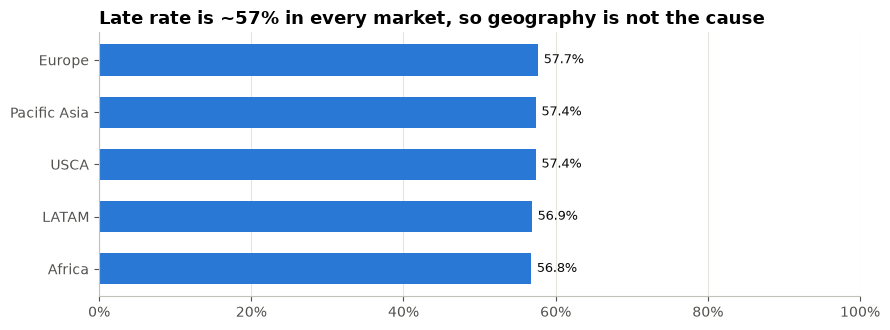

In [8]:
fig, ax = plt.subplots(figsize=(9, 3.4))
m = markets.sort_values("late_rate")
ax.barh(m["market"], m["late_rate"], color=BLUE, height=0.6)
for y, v in enumerate(m["late_rate"]):
    ax.annotate(f"{v:.1%}", (v, y), xytext=(4, 0), textcoords="offset points", va="center", color=INK, fontsize=9)
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(pct)
ax.set_title("Late rate is ~57% in every market, so geography is not the cause")
ax.grid(axis="x", color="#e5e4df"); ax.set_axisbelow(True)
save(fig, "02_late_rate_by_market.png")

The late rate barely moves by market (57–58%), region or customer segment, but swings from 40% to 100% by shipping mode. **The problem is the delivery promise, not the geography.** That matters, because "fix the slow regions" would have been the obvious but wrong recommendation.

## Q4 · Where to act first: risk ranking

The ranking looks at where the **most late lines** are, by region and mode, and ranks them with a window function.

In [9]:
risk = q("""
    WITH combo AS (
        SELECT order_region, shipping_mode,
               COUNT(*)           AS lines,
               SUM(is_late)       AS late_lines,
               AVG(is_late)       AS late_rate,
               SUM(net_sales) FILTER (WHERE is_late = 1) AS late_sales
        FROM shipped
        GROUP BY order_region, shipping_mode
    )
    SELECT RANK() OVER (ORDER BY late_lines DESC) AS priority,
           order_region, shipping_mode, lines, late_lines,
           ROUND(late_rate, 3) AS late_rate,
           ROUND(late_sales)   AS late_sales,
           ROUND(100.0 * SUM(late_lines) OVER (ORDER BY late_lines DESC) / SUM(late_lines) OVER (), 1) AS cumulative_pct_of_late
    FROM combo
    QUALIFY priority <= 10
    ORDER BY priority
""")
risk

,priority,order_region,shipping_mode,lines,late_lines,late_rate,late_sales,cumulative_pct_of_late
0,1,Central America,Standard Class,16382,"6,571.00",0.40,"1,192,804.00",6.60
1,2,Western Europe,Standard Class,15143,"6,089.00",0.40,"1,212,879.00",12.80
2,3,Western Europe,Second Class,5206,"4,236.00",0.81,"810,961.00",17.10
3,4,Central America,First Class,4185,"4,185.00",1.00,"757,936.00",21.30
4,5,Central America,Second Class,5250,"4,111.00",0.78,"727,633.00",25.50
5,6,Western Europe,First Class,4107,"4,107.00",1.00,"801,200.00",29.60
6,7,South America,Standard Class,8587,"3,437.00",0.40,"611,267.00",33.10
7,8,Oceania,Standard Class,5887,"2,387.00",0.41,"420,600.00",35.50
8,9,Southeast Asia,Standard Class,5477,"2,236.00",0.41,"404,663.00",40.00
9,9,Northern Europe,Standard Class,5666,"2,236.00",0.40,"434,194.00",40.00


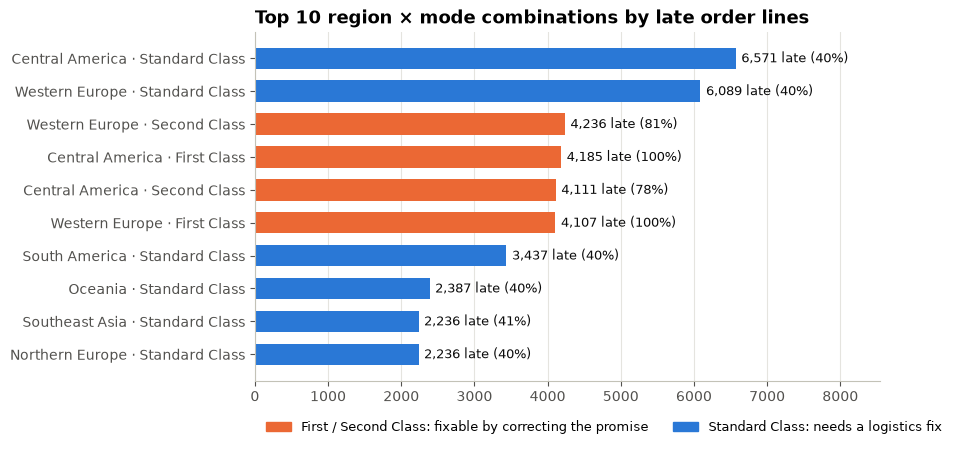

In [10]:
r = risk.sort_values("late_lines")
labels = r["order_region"] + " · " + r["shipping_mode"]
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(labels, r["late_lines"], color=[ORANGE if m in ("First Class", "Second Class") else BLUE for m in r["shipping_mode"]], height=0.65)
for y, (v, rate) in enumerate(zip(r["late_lines"], r["late_rate"])):
    ax.annotate(f"{v:,.0f} late ({rate:.0%})", (v, y), xytext=(4, 0), textcoords="offset points", va="center", color=INK, fontsize=9)
ax.set_xlim(0, r["late_lines"].max() * 1.3)
ax.set_title("Top 10 region × mode combinations by late order lines")
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=ORANGE, label="First / Second Class: fixable by correcting the promise"),
                   Patch(color=BLUE, label="Standard Class: needs a logistics fix")],
          frameon=False, loc="upper left", bbox_to_anchor=(0, -0.08), ncol=2, fontsize=9)
ax.grid(axis="x", color="#e5e4df"); ax.set_axisbelow(True)
save(fig, "03_risk_ranking.png")

**Central America and Western Europe** dominate because they are the biggest regions. These 10 combinations (out of ~90) hold **40% of all late lines**, so a focused team can tackle most of the problem. The First and Second Class rows are the quickest wins, because the fix is a policy change rather than a logistics project.

## Q5 · Does lateness cost profit? Where is profit lost?

In [11]:
q("""
    WITH o AS (
        SELECT order_id, MAX(is_late) AS late, SUM(profit) AS profit, SUM(net_sales) AS sales
        FROM shipped GROUP BY order_id
    )
    SELECT CASE WHEN late = 1 THEN 'Late order' ELSE 'On-time order' END AS order_type,
           COUNT(*)                     AS orders,
           ROUND(AVG(sales), 2)         AS avg_order_value,
           ROUND(AVG(profit), 2)        AS avg_profit_per_order,
           ROUND(100 * AVG(CASE WHEN profit < 0 THEN 1 ELSE 0 END), 1) AS pct_orders_loss_making
    FROM o GROUP BY 1
""")

,order_type,orders,avg_order_value,avg_profit_per_order,pct_orders_loss_making
0,On-time order,26849,505.13,62.06,20.90
1,Late order,36048,501.62,59.37,21.30


In [12]:
q("""
    SELECT ROUND(100 * AVG(CASE WHEN profit < 0 THEN 1 ELSE 0 END), 1) AS pct_lines_loss_making,
           ROUND(SUM(profit) FILTER (WHERE profit < 0))                 AS profit_lost_on_loss_lines,
           ROUND(SUM(profit))                                           AS net_profit
    FROM orders
""")

,pct_lines_loss_making,profit_lost_on_loss_lines,net_profit
0,18.70,"-3,883,547.00","3,966,903.00"


Late orders earn about the same profit as on-time orders, so in this data lateness shows up as **customer-experience and churn risk, not lost margin on the order itself.** Separately, about **19% of order lines lose money**, around **$3.9M lost on those lines** against only $4.0M net profit. That margin leak is a separate pricing workstream, worth a follow-up analysis.

## Q6 · Where is fraud risk concentrated?

In [13]:
q("""
    SELECT payment_type,
           COUNT(*)                                               AS lines,
           SUM(CASE WHEN is_suspected_fraud THEN 1 ELSE 0 END)    AS fraud_lines,
           ROUND(100 * AVG(CASE WHEN is_suspected_fraud THEN 1 ELSE 0 END), 1) AS fraud_rate_pct,
           ROUND(SUM(net_sales) FILTER (WHERE is_suspected_fraud)) AS fraud_sales
    FROM orders GROUP BY payment_type ORDER BY fraud_lines DESC
""")

,payment_type,lines,fraud_lines,fraud_rate_pct,fraud_sales
0,TRANSFER,49883,"4,062.00",8.10,"741,492.00"
1,DEBIT,69295,0.00,0.00,NaN
2,CASH,19616,0.00,0.00,NaN
3,PAYMENT,41725,0.00,0.00,NaN


**Every suspected-fraud order is a bank TRANSFER**: 8.1% of transfer lines, around $0.74M of sales. Cash, debit and payment orders have no fraud flags. A targeted check on transfer payments (for example, holding shipment until funds clear) would cover 100% of flagged cases while leaving other payment types untouched.

## Q7 · What if delivery promises matched reality?

Scenario: reset each mode's promise to what the warehouse actually achieves (First Class = 2 days, Second Class = 4, Same Day = 1, Standard unchanged at 4). Same shipments, honest promises.

In [14]:
scenario = q("""
    WITH promise AS (
        SELECT * FROM (VALUES ('First Class', 2), ('Second Class', 4), ('Standard Class', 4), ('Same Day', 1))
                 AS t(shipping_mode, realistic_days)
    )
    SELECT s.shipping_mode,
           ROUND(AVG(s.is_late), 3)                                                   AS late_rate_now,
           ROUND(AVG(CASE WHEN s.days_actual > p.realistic_days THEN 1 ELSE 0 END), 3) AS late_rate_realistic,
           COUNT(*)                                                                   AS lines
    FROM shipped s JOIN promise p USING (shipping_mode)
    GROUP BY s.shipping_mode
    ORDER BY late_rate_now DESC
""")
total = q("""
    WITH promise AS (SELECT * FROM (VALUES ('First Class', 2), ('Second Class', 4), ('Standard Class', 4), ('Same Day', 1)) AS t(shipping_mode, realistic_days))
    SELECT ROUND(AVG(s.is_late), 3) AS late_now,
           ROUND(AVG(CASE WHEN s.days_actual > p.realistic_days THEN 1 ELSE 0 END), 3) AS late_realistic
    FROM shipped s JOIN promise p USING (shipping_mode)
""")
print(f"Overall late rate: {total.late_now[0]:.1%} now -> {total.late_realistic[0]:.1%} with realistic promises")
scenario

Overall late rate: 57.3% now -> 31.5% with realistic promises


,shipping_mode,late_rate_now,late_rate_realistic,lines
0,First Class,1.00,0.00,26513
1,Second Class,0.80,0.40,33806
2,Same Day,0.48,0.00,9293
3,Standard Class,0.40,0.40,103153


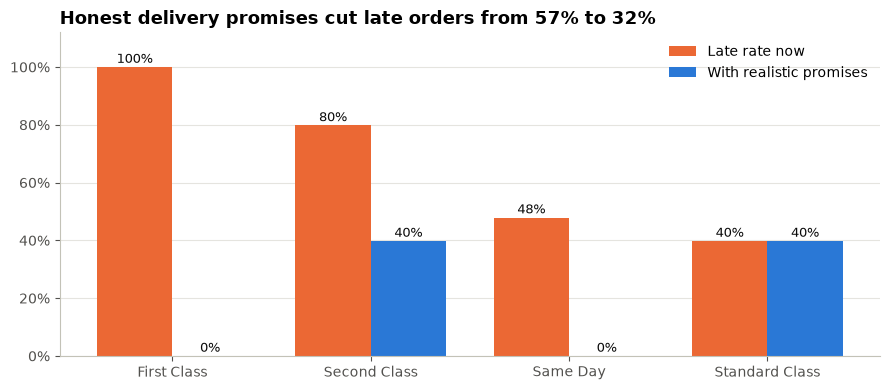

In [15]:
x = np.arange(len(scenario)); w = 0.38
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(x - w/2, scenario["late_rate_now"], w, color=ORANGE, label="Late rate now")
ax.bar(x + w/2, scenario["late_rate_realistic"], w, color=BLUE, label="With realistic promises")
for i, r in scenario.iterrows():
    ax.annotate(f"{r.late_rate_now:.0%}", (i - w/2, r.late_rate_now), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9, color=INK)
    ax.annotate(f"{r.late_rate_realistic:.0%}", (i + w/2, r.late_rate_realistic), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=9, color=INK)
ax.set_xticks(x, scenario["shipping_mode"]); ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, 1.12)
ax.legend(frameon=False, loc="upper right")
ax.set_title(f"Honest delivery promises cut late orders from {total.late_now[0]:.0%} to {total.late_realistic[0]:.0%}")
ax.grid(axis="y", color="#e5e4df"); ax.set_axisbelow(True)
save(fig, "04_scenario_realistic_promises.png")

**With realistic promises, the overall late rate falls from about 57% to 32%**, with no change to warehouses or carriers. First Class and Same Day go to 0% late. The remaining lateness is in Second and Standard Class (actual times vary from 2 to 6 days), which is where a genuine logistics fix would be needed.

## Recommendations

1. **Re-set delivery promises** for First Class (1 → 2 days) and Second Class (2 → 4 days) at checkout. This is the quickest, cheapest fix and cuts late orders by about 25 percentage points.
2. **If faster delivery is the goal**, investigate why Second and Standard Class vary from 2 to 6 days, starting with **Central America and Western Europe Standard Class**, the largest pools of late lines.
3. **Don't spend on region-specific logistics fixes.** Regions perform almost identically, so geography isn't the cause.
4. **Add a fraud check for bank-transfer payments**, where 100% of suspected fraud occurs.
5. **Open a pricing workstream on loss-making lines** (~19% of lines lose money, about $3.9M in total).

*Caveat:* volume and product range change sharply from Oct 2017 (see notebook 01), so the analysis focuses on process metrics rather than revenue trends.